In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.patches as patches
import matplotlib.patheffects as path_effects
from scipy.stats import bootstrap
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
gammas_S1 = [0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999, 0.9995, 0.9999, 0.99995, 0.99999, 0.999995]

In [3]:
maxcost_S1 = pd.read_csv(f'sweep_s1_gamma/gamma_0500000/results/evaluation.csv')['Stage 0'].median()

In [4]:
best_cost_S1 = []
lower_S1 = []
upper_S1 = []
for g in gammas_S1:
    gstr = str(g)[2:].ljust(6, '0')
    data = pd.read_csv(f'sweep_s1_gamma/gamma_0{gstr}/results/evaluation.csv')['Stage 21']
    C = ((maxcost_S1 - data.mean()) / maxcost_S1) * 100
    res = bootstrap(
        (data,), np.mean, axis=0, confidence_level=0.95, n_resamples=10000
    )
    ci_low, ci_high = res.confidence_interval
    Clower = ((maxcost_S1 - ci_low) / maxcost_S1) * 100
    Cupper = ((maxcost_S1 - ci_high) / maxcost_S1) * 100
    best_cost_S1.append(C)
    lower_S1.append(C - Cupper)
    upper_S1.append(Clower - C)

Text(0.5, 1.0, 'Round 1: Fix $\\alpha=0.2$, Vary $\\gamma$')

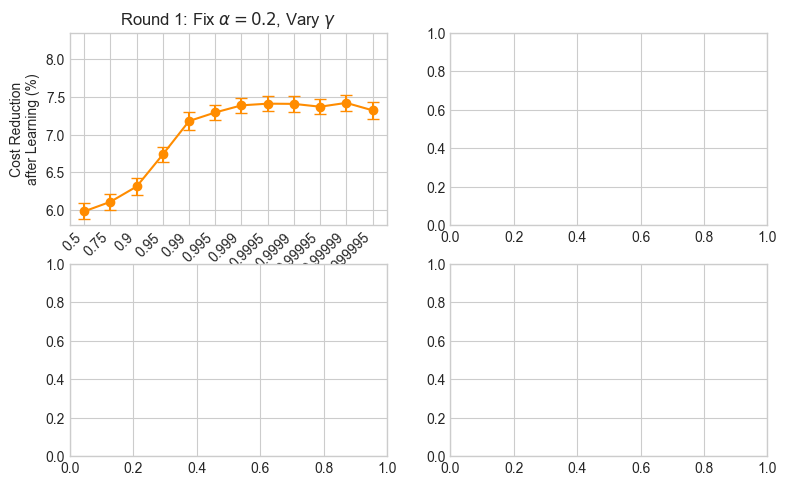

In [5]:
fig, axarr = plt.subplots(2, 2, figsize=(9, 5.5))
axarr[0, 0].errorbar(range(len(gammas_S1)), best_cost_S1, yerr=[lower_S1, upper_S1], c='darkorange', fmt="-o", capsize=4)
axarr[0, 0].set_xticks(range(len(gammas_S1)))
axarr[0, 0].set_xticklabels(gammas_S1, rotation=45, ha='right')
axarr[0, 0].set_ylim(5.8, 8.35)
axarr[0, 0].set_ylabel("Cost Reduction\nafter Learning (%)")
axarr[0, 0].set_xlabel(r"Discounting Factor ($\gamma$)")
axarr[0, 0].set_title(r"Round 1: Fix $\alpha=0.2$, Vary $\gamma$")

In [6]:
alphas_S2 = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

In [7]:
maxcost_S2 = pd.read_csv(f'sweep_s2_alpha/alpha_0050/results/evaluation.csv')['Stage 0'].median()

In [8]:
best_cost_S2 = []
lower_S2 = []
upper_S2 = []
for g in alphas_S2:
    gstr = str(g)[2:].ljust(3, '0')
    data = pd.read_csv(f'sweep_s2_alpha/alpha_0{gstr}/results/evaluation.csv')['Stage 21']
    C = ((maxcost_S2 - data.mean()) / maxcost_S2) * 100
    res = bootstrap(
        (data,), np.mean, axis=0, confidence_level=0.95, n_resamples=10000
    )
    ci_low, ci_high = res.confidence_interval
    Clower = ((maxcost_S2 - ci_low) / maxcost_S2) * 100
    Cupper = ((maxcost_S2 - ci_high) / maxcost_S2) * 100
    best_cost_S2.append(C)
    lower_S2.append(C - Cupper)
    upper_S2.append(Clower - C)

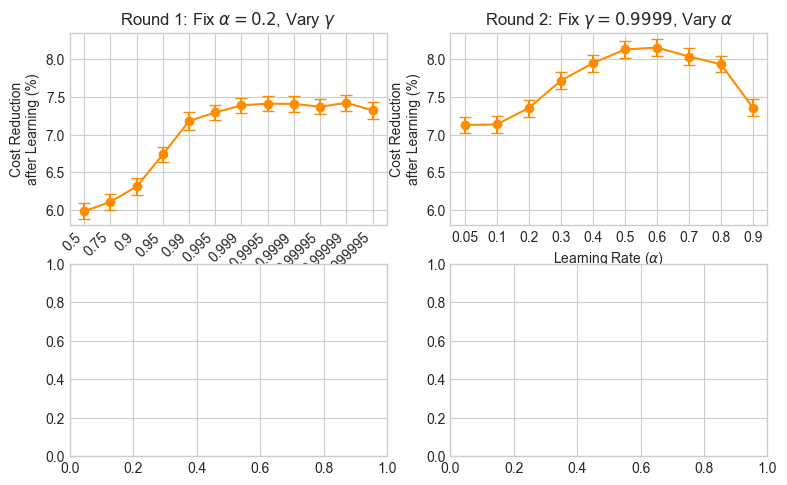

In [9]:
axarr[0, 1].errorbar(range(len(alphas_S2)), best_cost_S2, yerr=[lower_S2, upper_S2], c='darkorange', fmt="-o", capsize=4)
axarr[0, 1].set_xticks(range(len(alphas_S2)))
axarr[0, 1].set_xticklabels(alphas_S2)
axarr[0, 1].set_ylim(5.8, 8.35)
axarr[0, 1].set_ylabel("Cost Reduction\nafter Learning (%)")
axarr[0, 1].set_xlabel(r"Learning Rate ($\alpha$)")
axarr[0, 1].set_title(r"Round 2: Fix $\gamma=0.9999$, Vary $\alpha$")
fig

In [10]:
gammas_S3 = [0.9995, 0.99965, 0.9998, 0.9999, 0.99991, 0.99993, 0.99995]

In [11]:
maxcost_S3 = pd.read_csv(f'sweep_s3_gamma/gamma_099990/results/evaluation.csv')['Stage 0'].median()

In [12]:
best_cost_S3 = []
lower_S3 = []
upper_S3 = []
for g in gammas_S3:
    gstr = str(g)[2:].ljust(5, '0')
    data = pd.read_csv(f'sweep_s3_gamma/gamma_0{gstr}/results/evaluation.csv')['Stage 21']
    C = ((maxcost_S3 - data.mean()) / maxcost_S3) * 100
    res = bootstrap(
        (data,), np.mean, axis=0, confidence_level=0.95, n_resamples=10000
    )
    ci_low, ci_high = res.confidence_interval
    Clower = ((maxcost_S3 - ci_low) / maxcost_S3) * 100
    Cupper = ((maxcost_S3 - ci_high) / maxcost_S3) * 100
    best_cost_S3.append(C)
    lower_S3.append(C - Cupper)
    upper_S3.append(Clower - C)

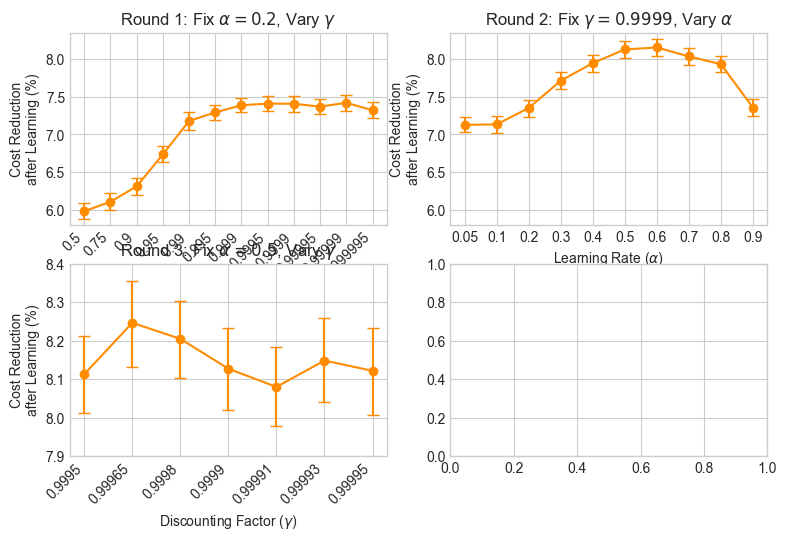

In [13]:
axarr[1, 0].errorbar(range(len(gammas_S3)), best_cost_S3, yerr=[lower_S3, upper_S3], c='darkorange', fmt="-o", capsize=4)
axarr[1, 0].set_xticks(range(len(gammas_S3)))
axarr[1, 0].set_xticklabels(gammas_S3, rotation=45, ha='right')
axarr[1, 0].set_ylim(7.9, 8.4)
axarr[1, 0].set_ylabel("Cost Reduction\nafter Learning (%)")
axarr[1, 0].set_xlabel(r"Discounting Factor ($\gamma$)")
axarr[1, 0].set_title(r"Round 3: Fix $\alpha=0.5$, Vary $\gamma$")
fig

In [14]:
alpha_S4 = [0.4, 0.433, 0.466, 0.5, 0.533, 0.566, 0.6]

In [15]:
maxcost_S4 = pd.read_csv(f'sweep_s4_alpha/alpha_0400/results/evaluation.csv')['Stage 0'].median()

In [16]:
best_cost_S4 = []
lower_S4 = []
upper_S4 = []
for g in alpha_S4:
    gstr = str(g)[2:].ljust(3, '0')
    data = pd.read_csv(f'sweep_s4_alpha/alpha_0{gstr}/results/evaluation.csv')['Stage 21']
    C = ((maxcost_S4 - data.mean()) / maxcost_S4) * 100
    res = bootstrap(
        (data,), np.mean, axis=0, confidence_level=0.95, n_resamples=10000
    )
    ci_low, ci_high = res.confidence_interval
    Clower = ((maxcost_S4 - ci_low) / maxcost_S4) * 100
    Cupper = ((maxcost_S4 - ci_high) / maxcost_S4) * 100
    best_cost_S4.append(C)
    lower_S4.append(C - Cupper)
    upper_S4.append(Clower - C)

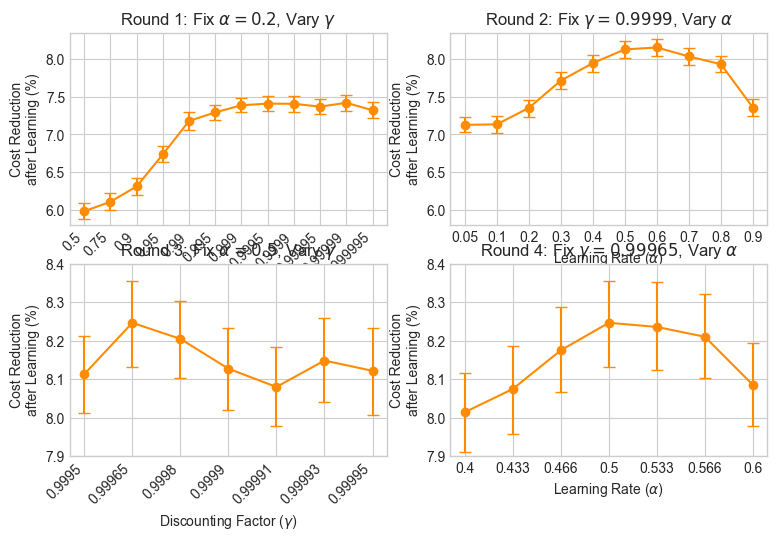

In [17]:
axarr[1,1].errorbar(range(len(alpha_S4)), best_cost_S4, yerr=[lower_S4, upper_S4], c='darkorange', fmt="-o", capsize=4)
axarr[1,1].set_xticks(range(len(alpha_S4)))
axarr[1,1].set_xticklabels(alpha_S4)
axarr[1,1].set_ylim(7.9, 8.4)
axarr[1,1].set_ylabel("Cost Reduction\nafter Learning (%)")
axarr[1,1].set_xlabel(r"Learning Rate ($\alpha$)")
axarr[1,1].set_title(r"Round 4: Fix $\gamma=0.99965$, Vary $\alpha$")
fig

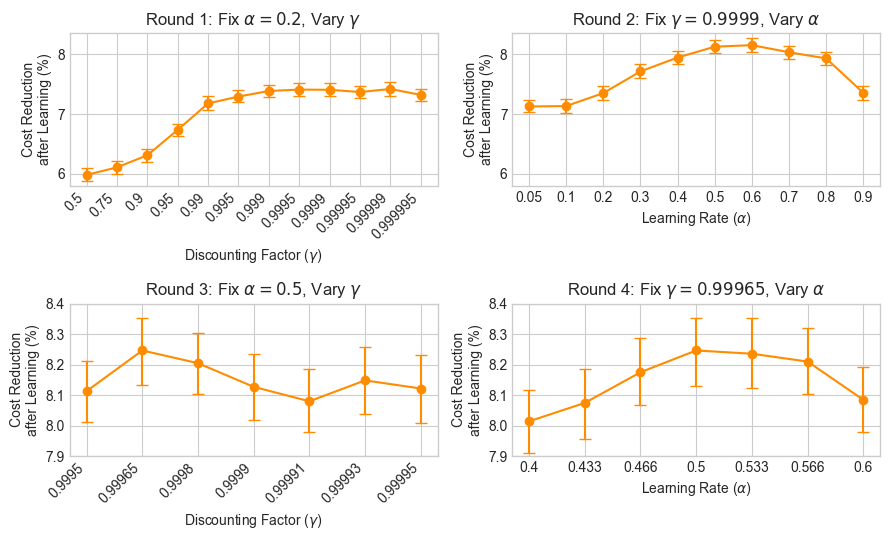

In [18]:
fig.tight_layout()
fig

In [19]:
fig.savefig("../../../plt/param_sweep.pdf")